In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("DS605 Lab 8")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Environment setup successful!")

DS605 Lab 8
NumPy version: 2.5.1
Pandas version: 3.0.5
Scikit-learn version: 1.9.0
Environment setup successful!


In [2]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
banknote_authentication = fetch_ucirepo(id=267) 
  
# data (as pandas dataframes) 
X = banknote_authentication.data.features 
y = banknote_authentication.data.targets 
  
# metadata 
print(banknote_authentication.metadata) 
  
# variable information 
print(banknote_authentication.variables) 


{'uci_id': 267, 'name': 'Banknote Authentication', 'repository_url': 'https://archive.ics.uci.edu/dataset/267/banknote+authentication', 'data_url': 'https://archive.ics.uci.edu/static/public/267/data.csv', 'abstract': 'Data were extracted from images that were taken for the evaluation of an authentication procedure for banknotes.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1372, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2012, 'last_updated': 'Fri Feb 16 2024', 'dataset_doi': '10.24432/C55P57', 'creators': ['Volker Lohweg'], 'intro_paper': None, 'additional_info': {'summary': 'Data were extracted from images that were taken from genuine and forged banknote-like specimens.  For digitization, an industrial camera usually used for print inspection was used. The final im

In [4]:
# Check the number of samples and features
print("Dataset shape:", banknote_authentication.data.shape)

# Check the target shape
print("Target shape:", banknote_authentication.data.targets.shape)

# Convert features into a DataFrame
X = pd.DataFrame(
    banknote_authentication.data.features,
    columns=banknote_authentication.variables["name"][:4]
)

# Store the target labels
y = banknote_authentication.data.targets

# Display the first five rows
print(X.head())
print(y[:5])

# Check for missing values
print("Missing values:")
print(X.isnull().sum())

# Check the number of samples in each class
print("\nClass distribution:")
print(y.value_counts())

Dataset shape: None
Target shape: (1372, 1)
name  variance  skewness  curtosis  entropy
0      3.62160    8.6661   -2.8073 -0.44699
1      4.54590    8.1674   -2.4586 -1.46210
2      3.86600   -2.6383    1.9242  0.10645
3      3.45660    9.5228   -4.0112 -3.59440
4      0.32924   -4.4552    4.5718 -0.98880
   class
0      0
1      0
2      0
3      0
4      0
Missing values:
name
variance    0
skewness    0
curtosis    0
entropy     0
dtype: int64

Class distribution:
class
0        762
1        610
Name: count, dtype: int64


In [5]:
def gini_impurity(y):
    if len(y) == 0:
        return 0

    probabilities = np.unique(y, return_counts=True)[1] / len(y)

    return 1 - np.sum(probabilities ** 2)

In [6]:
print(gini_impurity(np.array([0, 0, 0, 0])))
print(gini_impurity(np.array([0, 0, 1, 1])))
print(gini_impurity(np.array([0, 0, 0, 1])))

0.0
0.5
0.375


In [7]:
def entropy(y):
    if len(y) == 0:
        return 0

    probabilities = np.unique(y, return_counts=True)[1] / len(y)
    probabilities = probabilities[probabilities > 0]

    return -np.sum(probabilities * np.log2(probabilities))

In [8]:
print(entropy(np.array([0, 0, 0, 0])))
print(entropy(np.array([0, 0, 1, 1])))
print(entropy(np.array([0, 0, 0, 1])))

-0.0
1.0
0.8112781244591328


In [9]:
def weighted_impurity(y_left, y_right, criterion="gini"):
    n = len(y_left) + len(y_right)

    if n == 0:
        return 0

    impurity = gini_impurity if criterion == "gini" else entropy

    return (
        len(y_left) / n * impurity(y_left)
        + len(y_right) / n * impurity(y_right)
    )

In [10]:
y_left = np.array([0, 0])
y_right = np.array([1, 1])

print(weighted_impurity(y_left, y_right, "gini"))
print(weighted_impurity(y_left, y_right, "entropy"))

0.0
-0.0


In [11]:
def best_split(X, y, criterion="gini"):
    best_feature = None
    best_threshold = None
    best_impurity = float("inf")

    for feature in range(X.shape[1]):
        thresholds = np.unique(X[:, feature])

        for threshold in thresholds[:-1]:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            if not np.any(left_mask) or not np.any(right_mask):
                continue

            current_impurity = weighted_impurity(
                y[left_mask],
                y[right_mask],
                criterion
            )

            if current_impurity < best_impurity:
                best_impurity = current_impurity
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_impurity

In [12]:
X_test = np.array([
    [1.0],
    [2.0],
    [5.0],
    [6.0]
])

y_test = np.array([0, 0, 1, 1])

feature, threshold, impurity = best_split(X_test, y_test)

print("Best feature:", feature)
print("Best threshold:", threshold)
print("Weighted Gini:", impurity)

Best feature: 0
Best threshold: 2.0
Weighted Gini: 0.0


In [13]:
def build_tree(X, y, criterion="gini", depth=0, max_depth=5, min_samples_split=2):
    values, counts = np.unique(y, return_counts=True)
    prediction = values[np.argmax(counts)]

    node = {
        "prediction": prediction,
        "feature": None,
        "threshold": None,
        "left": None,
        "right": None
    }

    if len(values) == 1 or depth >= max_depth or len(y) < min_samples_split:
        return node

    feature, threshold, impurity = best_split(X, y, criterion)

    if feature is None:
        return node

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    if not np.any(left_mask) or not np.any(right_mask):
        return node

    node["feature"] = feature
    node["threshold"] = threshold
    node["left"] = build_tree(
        X[left_mask], y[left_mask], criterion,
        depth + 1, max_depth, min_samples_split
    )
    node["right"] = build_tree(
        X[right_mask], y[right_mask], criterion,
        depth + 1, max_depth, min_samples_split
    )

    return node

In [14]:
values, counts = np.unique(y, return_counts=True)
prediction = values[np.argmax(counts)]

In [17]:
def build_tree(X, y, criterion="gini", depth=0, max_depth=5, min_samples_split=2):
    values, counts = np.unique(y, return_counts=True)
    prediction = values[np.argmax(counts)]

    node = {
        "prediction": prediction,
        "feature": None,
        "threshold": None,
        "left": None,
        "right": None
    }

    if len(values) == 1 or depth >= max_depth or len(y) < min_samples_split:
        return node

    feature, threshold, impurity = best_split(X, y, criterion)

    if feature is None:
        return node

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    if not np.any(left_mask) or not np.any(right_mask):
        return node

    node["feature"] = feature
    node["threshold"] = threshold

    node["left"] = build_tree(
        X[left_mask], y[left_mask], criterion,
        depth + 1, max_depth, min_samples_split
    )

    node["right"] = build_tree(
        X[right_mask], y[right_mask], criterion,
        depth + 1, max_depth, min_samples_split
    )

    return node

In [18]:
X_test = np.array([[1.0], [2.0], [5.0], [6.0]])
y_test = np.array([0, 0, 1, 1])

tree = build_tree(X_test, y_test, max_depth=3)

predictions = predict_tree(tree, X_test)

print("Actual labels:", y_test)
print("Predictions:", predictions)
print("Accuracy:", np.mean(predictions == y_test))

NameError: name 'predict_tree' is not defined

In [19]:
def predict_one(node, sample):
    if node["feature"] is None:
        return node["prediction"]

    if sample[node["feature"]] <= node["threshold"]:
        return predict_one(node["left"], sample)

    return predict_one(node["right"], sample)


def predict_tree(tree, X):
    return np.array([predict_one(tree, sample) for sample in X])

In [20]:
X_test = np.array([[1.0], [2.0], [5.0], [6.0]])
y_test = np.array([0, 0, 1, 1])

tree = build_tree(X_test, y_test, max_depth=3)

predictions = predict_tree(tree, X_test)

print("Actual labels:", y_test)
print("Predictions:", predictions)
print("Accuracy:", np.mean(predictions == y_test))

Actual labels: [0 0 1 1]
Predictions: [0 0 1 1]
Accuracy: 1.0


In [21]:
X_2d = X[["variance", "skewness"]].to_numpy()
y_array = np.asarray(y).ravel()

print("Feature shape:", X_2d.shape)
print("Target shape:", y_array.shape)

Feature shape: (1372, 2)
Target shape: (1372,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_2d,
    y_array,
    test_size=0.2,
    random_state=42,
    stratify=y_array
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1097
Testing samples: 275


In [23]:
manual_tree = build_tree(
    X_train,
    y_train,
    criterion="gini",
    max_depth=5,
    min_samples_split=2
)

y_pred = predict_tree(manual_tree, X_test)

print("Test accuracy:", np.mean(y_pred == y_test))

Test accuracy: 0.9236363636363636


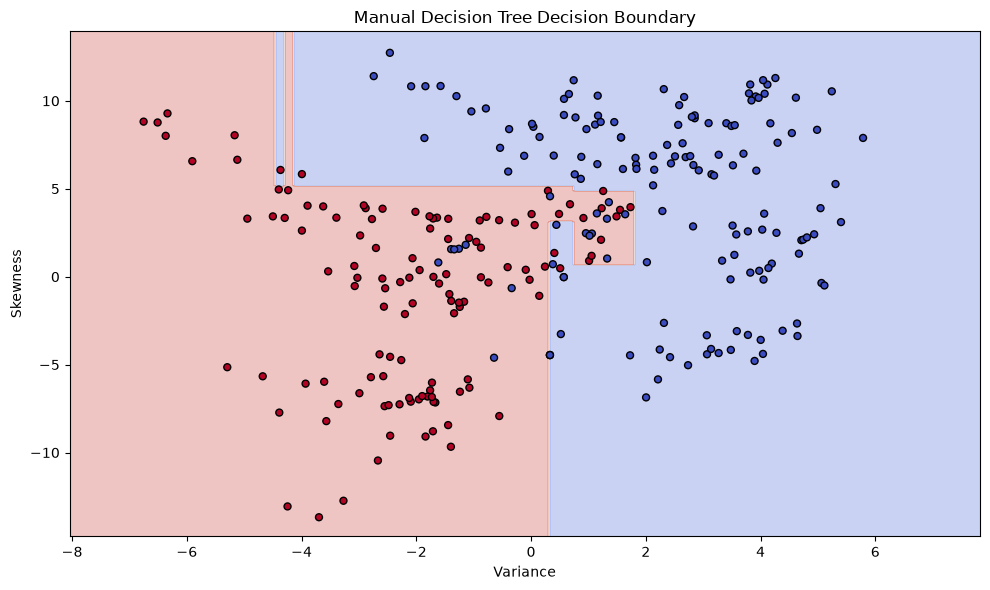

In [24]:
import matplotlib.pyplot as plt

x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = predict_tree(manual_tree, grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Manual Decision Tree Decision Boundary")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.tree import DecisionTreeClassifier

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sklearn_tree.fit(X_train, y_train)

sklearn_predictions = sklearn_tree.predict(X_test)

print("Manual Tree Accuracy:", np.mean(y_pred == y_test))
print("Scikit-learn Tree Accuracy:", np.mean(sklearn_predictions == y_test))

Manual Tree Accuracy: 0.9236363636363636
Scikit-learn Tree Accuracy: 0.9309090909090909


In [26]:
print("Manual predictions:", y_pred[:20])
print("Scikit-learn predictions:", sklearn_predictions[:20])

print(
    "Prediction agreement:",
    np.mean(y_pred == sklearn_predictions)
)

Manual predictions: [0 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 1 1 1 0]
Scikit-learn predictions: [0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 1 0]
Prediction agreement: 0.9927272727272727


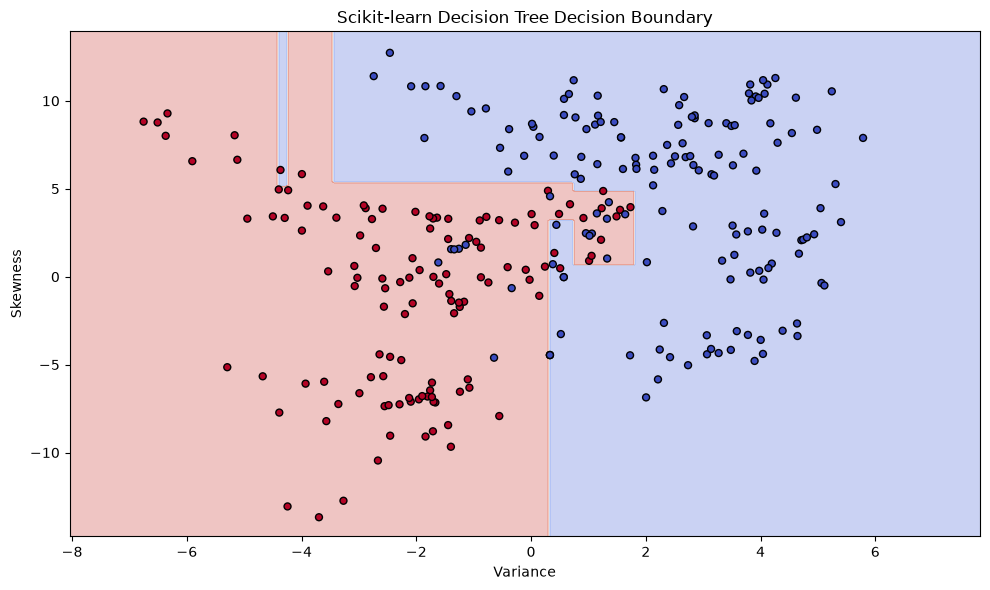

In [27]:
Z_sklearn = sklearn_tree.predict(grid)
Z_sklearn = Z_sklearn.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z_sklearn, alpha=0.3, cmap="coolwarm")
plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Scikit-learn Decision Tree Decision Boundary")
plt.tight_layout()
plt.show()

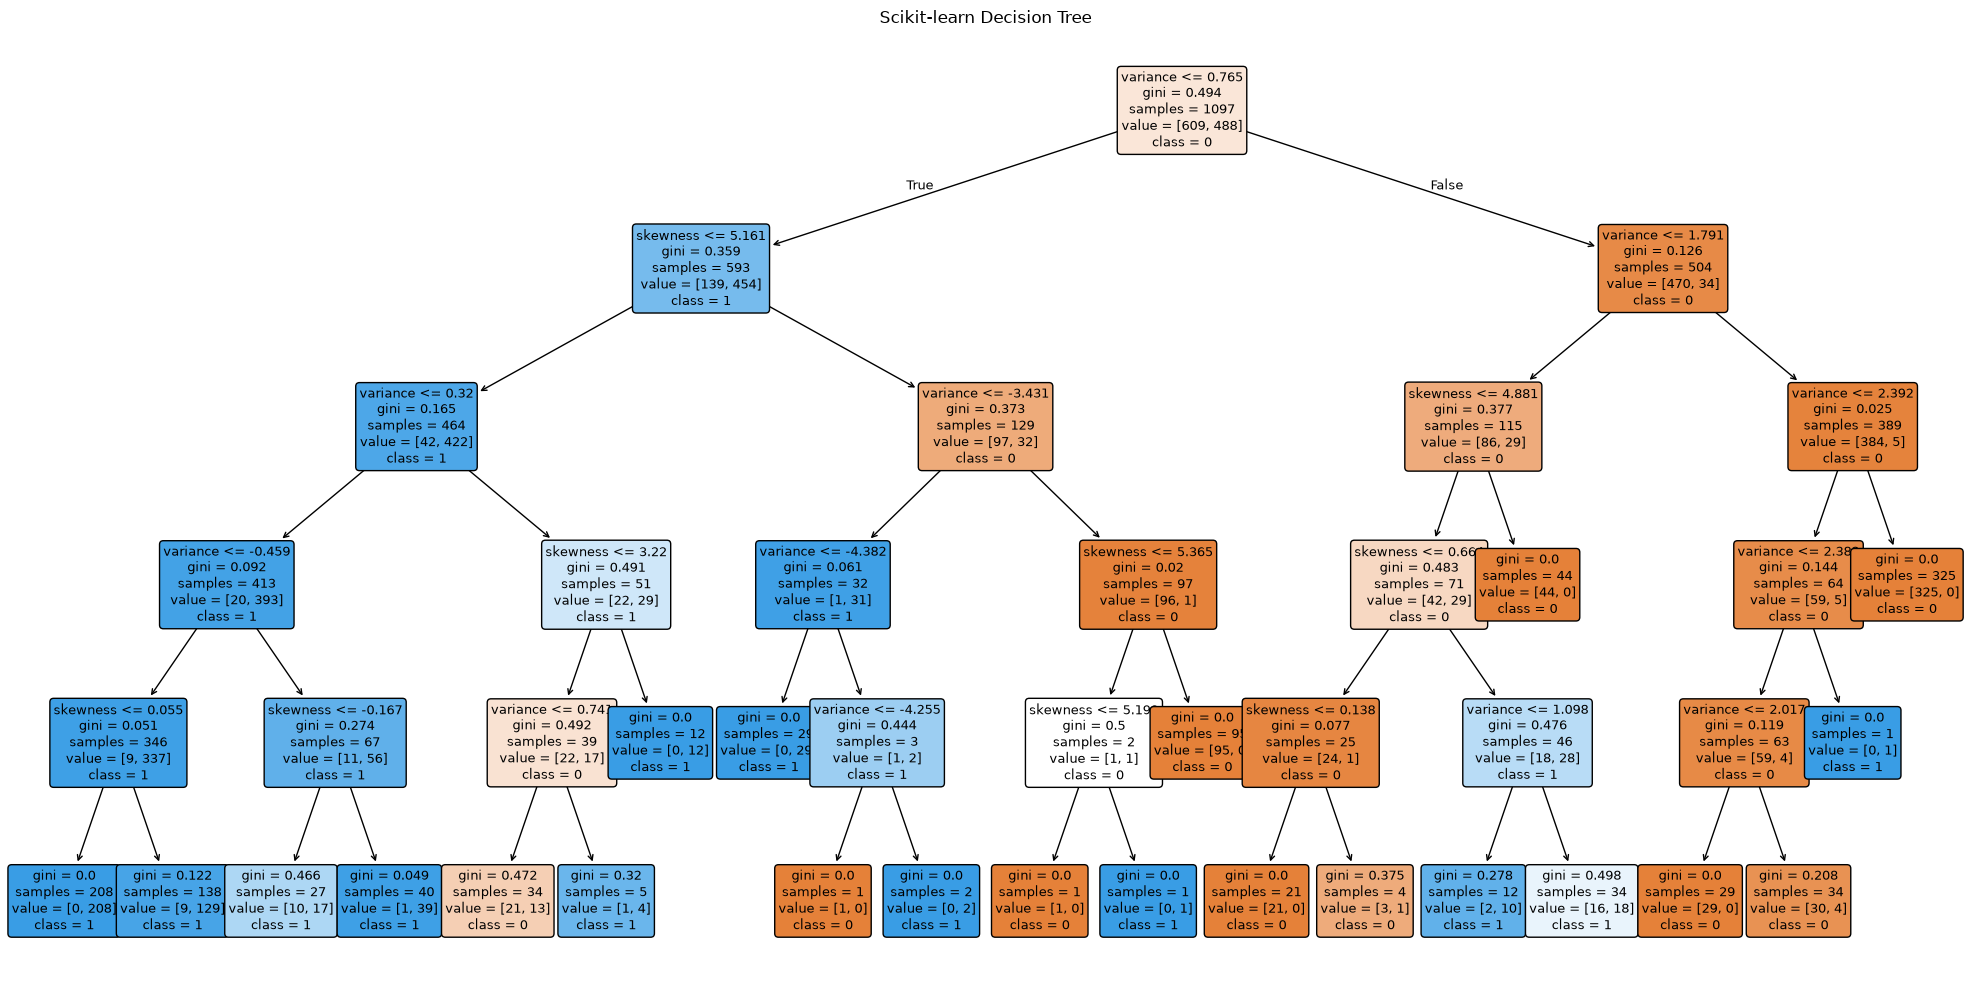

In [28]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    sklearn_tree,
    feature_names=["variance", "skewness"],
    class_names=[str(c) for c in sklearn_tree.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Scikit-learn Decision Tree")
plt.tight_layout()
plt.show()

In [29]:
def print_tree(node, feature_names, depth=0):
    if node["feature"] is None:
        print("    " * depth + f"Predict class: {node['prediction']}")
        return

    feature_name = feature_names[node["feature"]]

    print("    " * depth + f"If {feature_name} <= {node['threshold']:.4f}:")
    print_tree(node["left"], feature_names, depth + 1)

    print("    " * depth + "Else:")
    print_tree(node["right"], feature_names, depth + 1)


print_tree(manual_tree, ["variance", "skewness"])

If variance <= 0.7590:
    If skewness <= 5.1401:
        If variance <= 0.3180:
            If variance <= -0.4665:
                If skewness <= 0.0393:
                    Predict class: 1
                Else:
                    Predict class: 1
            Else:
                If skewness <= -0.1780:
                    Predict class: 1
                Else:
                    Predict class: 1
        Else:
            If skewness <= 3.1287:
                If variance <= 0.7405:
                    Predict class: 0
                Else:
                    Predict class: 1
            Else:
                Predict class: 1
    Else:
        If variance <= -4.1479:
            If variance <= -4.4779:
                Predict class: 1
            Else:
                If variance <= -4.2859:
                    Predict class: 0
                Else:
                    Predict class: 1
        Else:
            If skewness <= 5.2022:
                If variance <= 0.6365:
      

In [30]:
from sklearn.metrics import accuracy_score

tree_results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 10, None]:
        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        model.fit(X_train, y_train)

        train_predictions = model.predict(X_train)
        test_predictions = model.predict(X_test)

        tree_results.append({
            "criterion": criterion,
            "max_depth": depth,
            "train_accuracy": accuracy_score(y_train, train_predictions),
            "test_accuracy": accuracy_score(y_test, test_predictions)
        })

tree_results_df = pd.DataFrame(tree_results)
print(tree_results_df)

  criterion  max_depth  train_accuracy  test_accuracy
0      gini        2.0        0.901550       0.876364
1      gini        3.0        0.928897       0.909091
2      gini        5.0        0.948040       0.930909
3      gini       10.0        0.995442       0.923636
4      gini        NaN        1.000000       0.920000
5   entropy        2.0        0.901550       0.876364
6   entropy        3.0        0.928897       0.909091
7   entropy        5.0        0.948040       0.934545
8   entropy       10.0        0.991796       0.930909
9   entropy        NaN        1.000000       0.934545


Preparing the Data for SVM

In [31]:
X_train_mean = X_train.mean(axis=0)
X_train_std = X_train.std(axis=0)

X_train_std[X_train_std == 0] = 1

X_train_scaled = (X_train - X_train_mean) / X_train_std
X_test_scaled = (X_test - X_train_mean) / X_train_std

print("Scaled training mean:", X_train_scaled.mean(axis=0))
print("Scaled training standard deviation:", X_train_scaled.std(axis=0))

Scaled training mean: [-8.72390380e-17 -3.24666861e-16]
Scaled training standard deviation: [1. 1.]


In [32]:
y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

print("Original labels:", np.unique(y_train))
print("SVM labels:", np.unique(y_train_svm))

Original labels: [0 1]
SVM labels: [-1  1]


In [33]:
def train_linear_svm(X, y, learning_rate=0.001, epochs=1000, C=1.0):
    n_samples, n_features = X.shape

    w = np.zeros(n_features)
    b = 0.0

    for epoch in range(epochs):
        margins = y * (X @ w + b)
        violating = margins < 1

        dw = w - C * (X[violating].T @ y[violating]) / n_samples
        db = -C * np.sum(y[violating]) / n_samples

        w -= learning_rate * dw
        b -= learning_rate * db

    return w, b

In [35]:
w, b = train_linear_svm(
    X_train_scaled,
    y_train_svm,
    learning_rate=0.001,
    epochs=1000,
    C=1.0
)

decision_scores = X_test_scaled @ w + b
y_pred_svm = np.where(decision_scores >= 0, 1, -1)

print("Weights:", w)
print("Bias:", b)
print("Test accuracy:", np.mean(y_pred_svm == y_test_svm))

Weights: [-0.43019526 -0.25473474]
Bias: -0.11026800364630755
Test accuracy: 0.8872727272727273


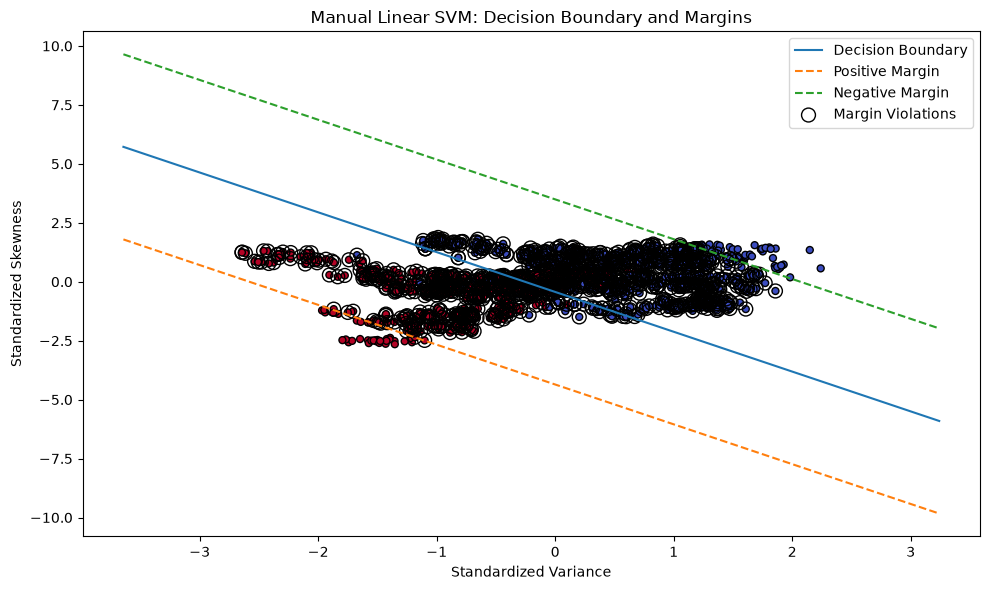

In [36]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=y_train_svm,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

x_values = np.linspace(
    X_train_scaled[:, 0].min() - 1,
    X_train_scaled[:, 0].max() + 1,
    300
)

if abs(w[1]) > 1e-10:
    decision_boundary = -(w[0] * x_values + b) / w[1]
    positive_margin = -(w[0] * x_values + b - 1) / w[1]
    negative_margin = -(w[0] * x_values + b + 1) / w[1]

    plt.plot(x_values, decision_boundary, label="Decision Boundary")
    plt.plot(x_values, positive_margin, "--", label="Positive Margin")
    plt.plot(x_values, negative_margin, "--", label="Negative Margin")

    margins = y_train_svm * (X_train_scaled @ w + b)
    violating = margins < 1

    plt.scatter(
        X_train_scaled[violating, 0],
        X_train_scaled[violating, 1],
        facecolors="none",
        edgecolors="black",
        s=100,
        label="Margin Violations"
    )

plt.xlabel("Standardized Variance")
plt.ylabel("Standardized Skewness")
plt.title("Manual Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

sklearn_svm = SVC(kernel="linear", C=1.0)

sklearn_svm.fit(X_train_scaled, y_train_svm)

sklearn_svm_predictions = sklearn_svm.predict(X_test_scaled)

print("Manual SVM Accuracy:", accuracy_score(y_test_svm, y_pred_svm))
print("Scikit-learn SVM Accuracy:", accuracy_score(y_test_svm, sklearn_svm_predictions))
print("Prediction Agreement:", np.mean(y_pred_svm == sklearn_svm_predictions))

Manual SVM Accuracy: 0.8872727272727273
Scikit-learn SVM Accuracy: 0.8763636363636363
Prediction Agreement: 0.96


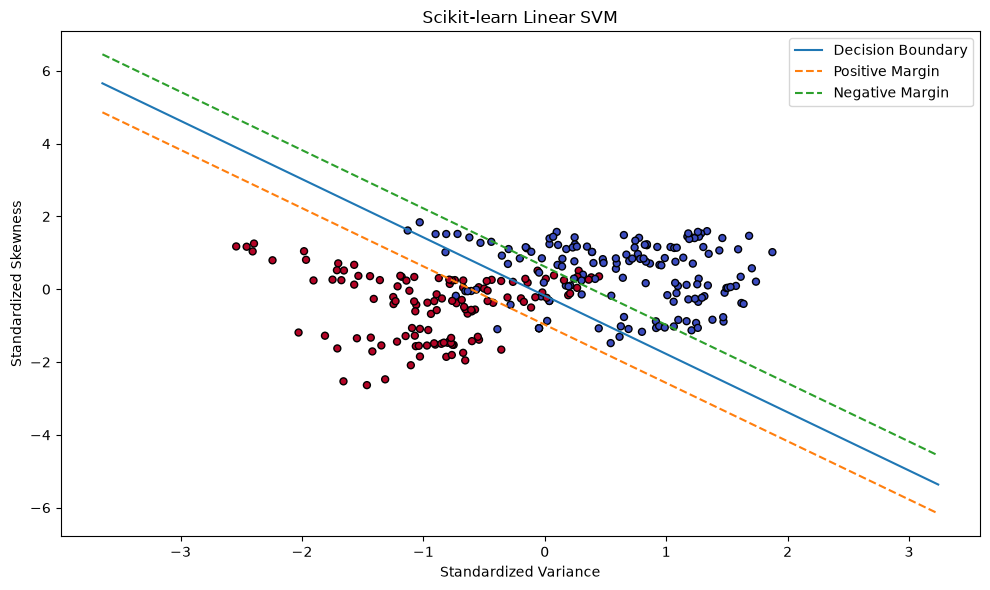

In [38]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test_scaled[:, 0],
    X_test_scaled[:, 1],
    c=y_test_svm,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

x_values = np.linspace(
    X_train_scaled[:, 0].min() - 1,
    X_train_scaled[:, 0].max() + 1,
    300
)

sklearn_w = sklearn_svm.coef_[0]
sklearn_b = sklearn_svm.intercept_[0]

if abs(sklearn_w[1]) > 1e-10:
    boundary = -(sklearn_w[0] * x_values + sklearn_b) / sklearn_w[1]
    upper_margin = -(sklearn_w[0] * x_values + sklearn_b - 1) / sklearn_w[1]
    lower_margin = -(sklearn_w[0] * x_values + sklearn_b + 1) / sklearn_w[1]

    plt.plot(x_values, boundary, label="Decision Boundary")
    plt.plot(x_values, upper_margin, "--", label="Positive Margin")
    plt.plot(x_values, lower_margin, "--", label="Negative Margin")

plt.xlabel("Standardized Variance")
plt.ylabel("Standardized Skewness")
plt.title("Scikit-learn Linear SVM")
plt.legend()
plt.tight_layout()
plt.show()

In [39]:
C_results = []

for c_value in [0.01, 0.1, 1.0, 10.0, 100.0]:
    w_temp, b_temp = train_linear_svm(
        X_train_scaled,
        y_train_svm,
        learning_rate=0.001,
        epochs=1000,
        C=c_value
    )

    train_pred = np.where(X_train_scaled @ w_temp + b_temp >= 0, 1, -1)
    test_pred = np.where(X_test_scaled @ w_temp + b_temp >= 0, 1, -1)

    C_results.append({
        "C": c_value,
        "Train Accuracy": np.mean(train_pred == y_train_svm),
        "Test Accuracy": np.mean(test_pred == y_test_svm)
    })

C_results_df = pd.DataFrame(C_results)
print(C_results_df)

        C  Train Accuracy  Test Accuracy
0    0.01        0.874202       0.887273
1    0.10        0.874202       0.887273
2    1.00        0.873291       0.887273
3   10.00        0.876026       0.883636
4  100.00        0.883318       0.883636


In [40]:
lr_results = []

for lr in [0.0001, 0.001, 0.01, 0.1]:
    w_temp, b_temp = train_linear_svm(
        X_train_scaled,
        y_train_svm,
        learning_rate=lr,
        epochs=1000,
        C=1.0
    )

    test_pred = np.where(X_test_scaled @ w_temp + b_temp >= 0, 1, -1)

    lr_results.append({
        "Learning Rate": lr,
        "Test Accuracy": np.mean(test_pred == y_test_svm)
    })

lr_results_df = pd.DataFrame(lr_results)
print(lr_results_df)

   Learning Rate  Test Accuracy
0         0.0001       0.883636
1         0.0010       0.887273
2         0.0100       0.865455
3         0.1000       0.865455


In [ ]:
epoch_results = []

for epochs in [100, 500, 1000, 5000, 10000]:
    w_temp, b_temp = train_linear_svm(
        X_train_scaled,
        y_train_svm,
        learning_rate=0.001,
        epochs=epochs,
        C=1.0
    )

    test_pred = np.where(X_test_scaled @ w_temp + b_temp >= 0, 1, -1)

    epoch_results.append({
        "Epochs": epochs,
        "Test Accuracy": np.mean(test_pred == y_test_svm)
    })

epoch_results_df = pd.DataFrame(epoch_results)
print(epoch_results_df)